# 01 · Data setup and splits

**Job:** get the COCO 2017 files and build the G9 splits.

| Output | Where |
|---|---|
| COCO annotation JSON files | `data/annotations/` |
| Split IDs (seed 42) and manifest | `data/splits/` |
| Images, as ZIP parts of 250 | `data/images_archives/` |
| Annotations limited to our images | `data/approved_annotations/` |
| Test-set balance check | `results/qa/test_stratification_diagnostic.csv` |

Run on Google Colab. All files are read from and written to `MyDrive/G9_Hybrid_RAG/`. No GPU needed.

## 1. Connect Google Drive

In [ ]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


## 2. Folders

In [ ]:
from pathlib import Path
import json
import shutil
import subprocess
import zipfile

PROJECT_DIR = Path("/content/drive/MyDrive/G9_Hybrid_RAG")
DATA_DIR = PROJECT_DIR / "data"
ANNOTATIONS_DIR = DATA_DIR / "annotations"
RAW_DIR = DATA_DIR / "raw"
SAMPLE_DIR = DATA_DIR / "images" / "sample"

for folder in (PROJECT_DIR, ANNOTATIONS_DIR, RAW_DIR, SAMPLE_DIR):
    folder.mkdir(parents=True, exist_ok=True)

print("✅ G9 folders ready")
print("Project:", PROJECT_DIR)

## 3. COCO annotation files

We need 4 JSON files. The ZIP is downloaded only if a file is missing.

In [ ]:
REQUIRED_FILES = [
    "captions_train2017.json",
    "captions_val2017.json",
    "instances_train2017.json",
    "instances_val2017.json",
]


def exists_nonempty(name):
    path = ANNOTATIONS_DIR / name
    return path.is_file() and path.stat().st_size > 100_000

missing_files = [name for name in REQUIRED_FILES if not exists_nonempty(name)]

for name in REQUIRED_FILES:
    status = "✅ FOUND" if exists_nonempty(name) else "❌ MISSING / TOO SMALL"
    print(f"{status}: {name}")

print("\nMissing files:", len(missing_files))

In [ ]:
ZIP_NAME = "annotations_trainval2017.zip"
ZIP_BACKUP = RAW_DIR / ZIP_NAME
ZIP_TEMP = Path("/content") / ZIP_NAME

if not missing_files:
    print("✅ All four annotations files already exist. Download skipped.")
else:
    # 1) Prefer a valid ZIP backup in Google Drive.
    if ZIP_BACKUP.exists() and zipfile.is_zipfile(ZIP_BACKUP):
        source_zip = ZIP_BACKUP
        print("Using ZIP backup from Drive:", source_zip)
    else:
        source_zip = ZIP_TEMP
        urls = [
            "https://images.cocodataset.org/annotations/annotations_trainval2017.zip",
            "http://images.cocodataset.org/annotations/annotations_trainval2017.zip",
        ]
        downloaded = False
        for url in urls:
            print("Downloading:", url)
            ZIP_TEMP.unlink(missing_ok=True)
            result = subprocess.run([
                "curl", "-fL", "--retry", "3", "--connect-timeout", "30",
                "--progress-bar", "-o", str(ZIP_TEMP), url
            ])
            if result.returncode == 0 and zipfile.is_zipfile(ZIP_TEMP):
                downloaded = True
                print("✅ Downloaded a valid ZIP")
                break
            print("⚠️ Download failed or file is not a ZIP")
        if not downloaded:
            raise RuntimeError("COCO ZIP download failed. Check the Colab connection and URL.")

    # 2) Verify that the archive contains every file we need.
    with zipfile.ZipFile(source_zip, "r") as z:
        members = set(z.namelist())
        expected = {"annotations/" + name for name in REQUIRED_FILES}
        assert expected.issubset(members), "ZIP is missing required JSON files"
        bad_entry = z.testzip()
        assert bad_entry is None, f"Corrupted ZIP entry: {bad_entry}"
        print("✅ ZIP integrity verified")

        # 3) Extract only missing files, using a temporary local file first.
        for name in missing_files:
            tmp_path = Path("/content") / name
            with z.open("annotations/" + name) as src, open(tmp_path, "wb") as dst:
                shutil.copyfileobj(src, dst)
            shutil.copy2(tmp_path, ANNOTATIONS_DIR / name)
            tmp_path.unlink(missing_ok=True)
            print("✅ Extracted:", name)

    # 4) Preserve the official ZIP in Drive for the team (if not already present).
    if source_zip == ZIP_TEMP and not zipfile.is_zipfile(ZIP_BACKUP):
        shutil.copy2(ZIP_TEMP, ZIP_BACKUP)
        print("✅ ZIP backup saved to Drive")

print("✅ Annotation preparation complete")

In [ ]:
for name in REQUIRED_FILES:
    path = ANNOTATIONS_DIR / name
    assert exists_nonempty(name), f"Missing or too small: {path}"
    size_mb = path.stat().st_size / (1024 ** 2)
    print(f"✅ {name}: {size_mb:.2f} MiB")

print("✅ All required annotation files are ready")

## 4. Read captions and image IDs

In [ ]:
import json
from pathlib import Path

# Our Google Drive project
project = Path("/content/drive/MyDrive/G9_Hybrid_RAG")

# COCO annotations folder
annotations_folder = project / "data/annotations"

# Load COCO train annotations
with open(annotations_folder / "captions_train2017.json") as f:
    train_data = json.load(f)

# Load COCO validation annotations
with open(annotations_folder / "captions_val2017.json") as f:
    val_data = json.load(f)

# Extract image IDs
train_ids = [img["id"] for img in train_data["images"]]
val_ids = [img["id"] for img in val_data["images"]]

print("Train images:", len(train_ids))
print("Validation images:", len(val_ids))

Train images: 118287
Validation images: 5000


In [ ]:
train_ids = [img["id"] for img in train_data["images"]]
val_ids = [img["id"] for img in val_data["images"]]

print("Train images:", len(train_ids))
print("Validation images:", len(val_ids))
print("First 5 train IDs:", train_ids[:5])

# Quality checks: every ID should be unique within each source.
assert len(train_ids) == len(set(train_ids)), "Duplicate train image IDs"
assert len(val_ids) == len(set(val_ids)), "Duplicate validation image IDs"
assert set(train_ids).isdisjoint(set(val_ids)), "Train/val IDs overlap"

print("✅ IDs are unique and train/val sources are disjoint")

## 5. Make the splits

- Knowledge base (KB): 10,000 images from `train2017`.
- Validation: 100 images from `val2017`.
- Test: 100 other images from `val2017`.

Seed 42. Image 139 is left out because we used it as a demo. An existing split file is never overwritten.

In [ ]:
import random

# Fixed seed for reproducibility
SEED = 42
rng = random.Random(SEED)

# Sort IDs to ensure consistent sampling
train_ids = sorted(train_ids)
val_ids = sorted(val_ids)

# 1. Select 10,000 images for Knowledge Base
kb_ids = sorted(rng.sample(train_ids, 10000))

# 2. Exclude image 139 (used in our learning example)
available_val_ids = [
    image_id for image_id in val_ids
    if image_id != 139
]

# 3. Select 200 different images
selected_val_ids = rng.sample(available_val_ids, 200)

# 4. Divide into validation and test
validation_ids = sorted(selected_val_ids[:100])
test_ids = sorted(selected_val_ids[100:])

print("Knowledge Base:", len(kb_ids))
print("Validation:", len(validation_ids))
print("Test:", len(test_ids))

Knowledge Base: 10000
Validation: 100
Test: 100


In [ ]:
# Check dataset sizes
assert len(kb_ids) == 10000
assert len(validation_ids) == 100
assert len(test_ids) == 100

# Check duplicates within each split
assert len(set(kb_ids)) == 10000
assert len(set(validation_ids)) == 100
assert len(set(test_ids)) == 100

# Check overlaps between splits
assert set(kb_ids).isdisjoint(validation_ids)
assert set(kb_ids).isdisjoint(test_ids)
assert set(validation_ids).isdisjoint(test_ids)

# Check total unique images
all_ids = kb_ids + validation_ids + test_ids

assert len(set(all_ids)) == 10200

print("✅ All checks passed!")
print("✅ No duplicate image IDs!")
print("✅ No overlap between datasets!")
print("✅ Total unique images:", len(set(all_ids)))

✅ All checks passed!
✅ No duplicate image IDs!
✅ No overlap between datasets!
✅ Total unique images: 10200


In [ ]:
# Create splits folder
splits_folder = project / "data/splits"
splits_folder.mkdir(parents=True, exist_ok=True)

# Organize our split information
splits = {
    "seed": SEED,
    "knowledge_base": kb_ids,
    "validation": validation_ids,
    "test": test_ids
}

# Save to JSON
split_path = splits_folder / "split_ids.json"

if split_path.exists():
    with open(split_path, "r") as f:
        existing_splits = json.load(f)

    assert existing_splits == splits, (
        "An existing split is different! "
        "Do not overwrite it without reviewing."
    )
    print("✅ Existing split matches our selection!")
else:
    with open(split_path, "w") as f:
        json.dump(splits, f, indent=2)

    print("✅ Dataset splits saved successfully!")

✅ Dataset splits saved successfully!


## 6. Image manifest

One row per image: split, ID, file name, source.

In [ ]:
import csv

# Map image IDs to image metadata
train_lookup = {
    img["id"]: img
    for img in train_data["images"]
}

val_lookup = {
    img["id"]: img
    for img in val_data["images"]
}

# Prepare manifest
rows = []

for split_name, image_ids, lookup, source in [
    ("knowledge_base", kb_ids, train_lookup, "train2017"),
    ("validation", validation_ids, val_lookup, "val2017"),
    ("test", test_ids, val_lookup, "val2017")
]:
    for image_id in image_ids:
        rows.append({
            "split": split_name,
            "image_id": image_id,
            "file_name": lookup[image_id]["file_name"],
            "source": source
        })

# Save CSV
manifest_path = splits_folder / "image_manifest.csv"

with open(manifest_path, "w", newline="") as f:
    writer = csv.DictWriter(
        f,
        fieldnames=["split", "image_id", "file_name", "source"]
    )

    writer.writeheader()
    writer.writerows(rows)

print("✅ Image manifest created!")
print("Total rows:", len(rows))

✅ Image manifest created!
Total rows: 10200


In [ ]:
import csv
from pathlib import Path
from collections import Counter

project = Path("/content/drive/MyDrive/G9_Hybrid_RAG")

manifest_path = project / "data/splits/image_manifest.csv"

# Read the manifest
with open(manifest_path, "r") as f:
    images = list(csv.DictReader(f))

# Count images per split
counts = Counter(img["split"] for img in images)

print("Total images:", len(images))
print("Images per split:", dict(counts))

# Quality checks
assert len(images) == 10200
assert counts["knowledge_base"] == 10000
assert counts["validation"] == 100
assert counts["test"] == 100

assert len(set(img["image_id"] for img in images)) == 10200

print("✅ Manifest verified!")

Total images: 10200
Images per split: {'knowledge_base': 10000, 'validation': 100, 'test': 100}
✅ Manifest verified!


## 7. Download the images

Images come from the official COCO server. Each one is checked, then stored in ZIP parts of 250. Finished parts are skipped on re-run.

In [ ]:
import requests
import time
from io import BytesIO
from PIL import Image

def download_image(image_info):

    source = image_info["source"]
    filename = image_info["file_name"]

    # Only allow the two approved COCO sources
    assert source in ["train2017", "val2017"]

    # Official COCO image URLs
    urls = [
        f"https://images.cocodataset.org/{source}/{filename}",
        f"http://images.cocodataset.org/{source}/{filename}"
    ]

    last_error = None

    for url in urls:
        for attempt in range(2):
            try:
                response = requests.get(
                    url,
                    timeout=(15, 60)
                )

                response.raise_for_status()

                image_bytes = response.content

                # Verify the downloaded image
                with Image.open(BytesIO(image_bytes)) as img:
                    assert img.format == "JPEG"
                    img.load()

                return image_bytes

            except (requests.RequestException,
                    OSError,
                    ValueError,
                    AssertionError) as e:

                last_error = e
                time.sleep(1)

    raise RuntimeError(
        f"Failed to download {filename}: {last_error}"
    )

print("✅ Download function ready!")

✅ Download function ready!


Downloading: 000000000074.jpg
Size: (640, 426)
Mode: RGB


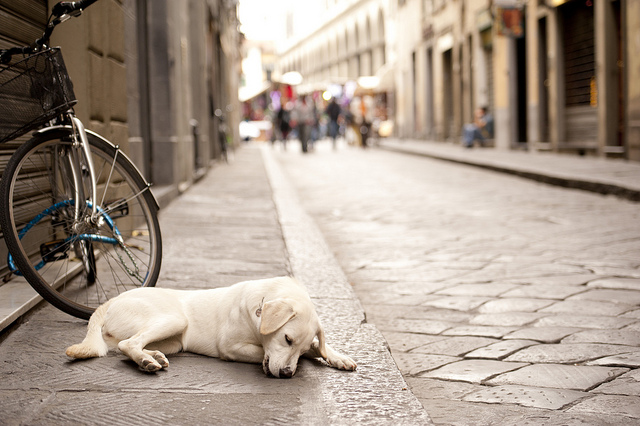

Downloading: 000000000113.jpg
Size: (416, 640)
Mode: RGB


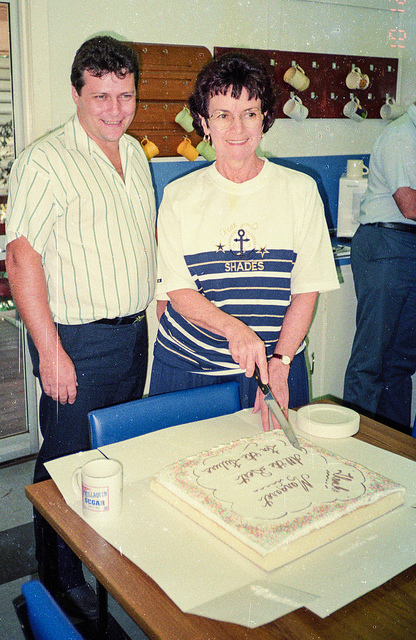

Downloading: 000000000133.jpg
Size: (640, 480)
Mode: RGB


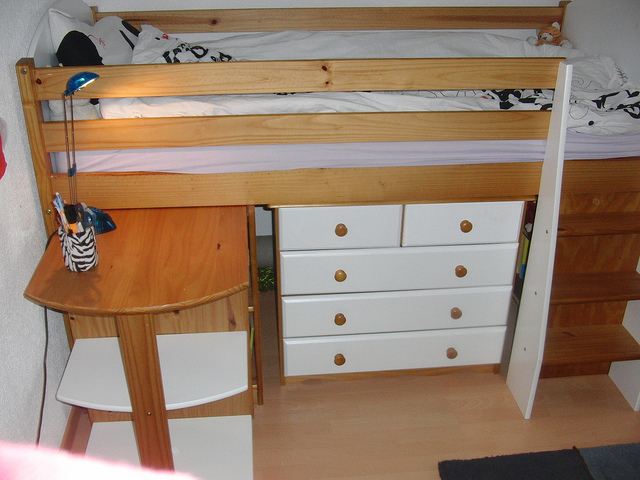

✅ Sample download test passed!


In [ ]:
from IPython.display import display

# Select first 3 KB images
sample_images = [
    img for img in images
    if img["split"] == "knowledge_base"
][:3]

for image_info in sample_images:

    print("Downloading:", image_info["file_name"])

    image_bytes = download_image(image_info)

    img = Image.open(BytesIO(image_bytes))

    print("Size:", img.size)
    print("Mode:", img.mode)

    display(img)

print("✅ Sample download test passed!")

In [ ]:
import zipfile
import shutil
from concurrent.futures import ThreadPoolExecutor, as_completed

BATCH_SIZE = 250
WORKERS = 4

archive_root = project / "data/images_archives"
archive_root.mkdir(parents=True, exist_ok=True)


def valid_archive(path, expected_names):
    """Check ZIP structure and expected filenames."""

    if not path.exists() or not zipfile.is_zipfile(path):
        return False

    try:
        with zipfile.ZipFile(path, "r") as z:
            names = z.namelist()
            return (
                len(names) == len(expected_names)
                and set(names) == expected_names
            )
    except (OSError, zipfile.BadZipFile):
        return False


def download_batch(split_name, batch_number, batch_rows):

    output_folder = archive_root / split_name
    output_folder.mkdir(parents=True, exist_ok=True)

    filename = f"part_{batch_number:03d}.zip"
    output_path = output_folder / filename

    expected_names = {
        f"{split_name}/{row['file_name']}"
        for row in batch_rows
    }

    # Skip previously completed archives
    if output_path.exists():
        if valid_archive(output_path, expected_names):
            print(f"⏭️ Already completed: {split_name}/{filename}")
            return

        raise RuntimeError(
            f"Existing archive is invalid: {output_path}"
        )

    # Build ZIP locally in Colab
    temp_path = Path("/content") / (
        f"{split_name}_{filename}"
    )

    errors = []

    with zipfile.ZipFile(
        temp_path, "w",
        compression=zipfile.ZIP_STORED
    ) as z:

        with ThreadPoolExecutor(max_workers=WORKERS) as executor:

            futures = {
                executor.submit(download_image, row): row
                for row in batch_rows
            }

            for future in as_completed(futures):
                row = futures[future]

                try:
                    image_bytes = future.result()

                    z.writestr(
                        f"{split_name}/{row['file_name']}",
                        image_bytes
                    )

                except Exception as e:
                    errors.append(
                        f"{row['file_name']}: {e}"
                    )

    # Do not save incomplete batches
    if errors:
        temp_path.unlink(missing_ok=True)
        print("Download errors:", errors[:5])
        raise RuntimeError(
            f"{len(errors)} images failed. "
            "Rerun to retry this batch."
        )

    # Verify local ZIP
    assert valid_archive(temp_path, expected_names)

    with zipfile.ZipFile(temp_path) as z:
        assert z.testzip() is None

    # Copy completed batch to Google Drive
    partial_path = output_folder / (filename + ".part")

    shutil.copyfile(temp_path, partial_path)

    assert partial_path.stat().st_size == temp_path.stat().st_size

    partial_path.replace(output_path)

    temp_path.unlink(missing_ok=True)

    print(f"✅ Saved: {split_name}/{filename}")


def download_split(split_name):

    selected = [
        row for row in images
        if row["split"] == split_name
    ]

    selected.sort(key=lambda row: int(row["image_id"]))

    total_batches = (
        len(selected) + BATCH_SIZE - 1
    ) // BATCH_SIZE

    for start in range(0, len(selected), BATCH_SIZE):

        batch_number = start // BATCH_SIZE + 1

        batch = selected[start:start + BATCH_SIZE]

        print(
            f"\n{split_name}: "
            f"batch {batch_number}/{total_batches}"
        )

        download_batch(
            split_name,
            batch_number,
            batch
        )

    print(f"✅ Completed: {split_name}")

In [ ]:
download_split("validation")
download_split("test")


validation: batch 1/1
✅ Saved: validation/part_001.zip
✅ Completed: validation

test: batch 1/1
✅ Saved: test/part_001.zip
✅ Completed: test


In [ ]:
download_split("knowledge_base")


knowledge_base: batch 1/40
⏭️ Already completed: knowledge_base/part_001.zip

knowledge_base: batch 2/40
⏭️ Already completed: knowledge_base/part_002.zip

knowledge_base: batch 3/40
⏭️ Already completed: knowledge_base/part_003.zip

knowledge_base: batch 4/40
⏭️ Already completed: knowledge_base/part_004.zip

knowledge_base: batch 5/40
⏭️ Already completed: knowledge_base/part_005.zip

knowledge_base: batch 6/40
⏭️ Already completed: knowledge_base/part_006.zip

knowledge_base: batch 7/40
⏭️ Already completed: knowledge_base/part_007.zip

knowledge_base: batch 8/40
⏭️ Already completed: knowledge_base/part_008.zip

knowledge_base: batch 9/40
⏭️ Already completed: knowledge_base/part_009.zip

knowledge_base: batch 10/40
⏭️ Already completed: knowledge_base/part_010.zip

knowledge_base: batch 11/40
⏭️ Already completed: knowledge_base/part_011.zip

knowledge_base: batch 12/40
⏭️ Already completed: knowledge_base/part_012.zip

knowledge_base: batch 13/40
⏭️ Already completed: knowledge_

## 8. Check every archive

CRC check, then the file names must match the manifest exactly.

In [ ]:
import csv
import zipfile
from pathlib import Path

project = Path("/content/drive/MyDrive/G9_Hybrid_RAG")

archive_root = project / "data/images_archives"
manifest_path = project / "data/splits/image_manifest.csv"

with open(manifest_path, newline="") as f:
    manifest = list(csv.DictReader(f))

expected_counts = {
    "knowledge_base": 10000,
    "validation": 100,
    "test": 100
}

for split, expected_count in expected_counts.items():

    expected_names = {
        f"{split}/{row['file_name']}"
        for row in manifest
        if row["split"] == split
    }

    found_names = []

    archives = sorted(
        (archive_root / split).glob("*.zip")
    )

    for archive in archives:

        with zipfile.ZipFile(archive) as z:

            # Verify archive contents (CRC)
            assert z.testzip() is None, (
                f"Corrupted ZIP: {archive}"
            )

            found_names.extend(z.namelist())

    assert len(found_names) == expected_count
    assert len(set(found_names)) == expected_count
    assert set(found_names) == expected_names

    print(f"✅ {split}: {len(found_names)} images verified")

print("\n✅ All 10,200 images verified!")

✅ knowledge_base: 10000 images verified
✅ validation: 100 images verified
✅ test: 100 images verified

✅ All 10,200 images verified!


## 9. Keep only the annotations of our images

Test annotations are **not** copied. Test captions are only for the final evaluation.

In [ ]:
import json
from pathlib import Path

project = Path("/content/drive/MyDrive/G9_Hybrid_RAG")

ann_folder = project / "data/annotations"
splits_folder = project / "data/splits"
output_folder = project / "data/approved_annotations"

output_folder.mkdir(parents=True, exist_ok=True)

# Read our official splits
with open(splits_folder / "split_ids.json") as f:
    splits = json.load(f)

kb_ids = set(splits["knowledge_base"])
validation_ids = set(splits["validation"])
test_ids = set(splits["test"])

# Read original annotations
def load_json(filename):
    with open(ann_folder / filename) as f:
        return json.load(f)

train_captions = load_json("captions_train2017.json")
val_captions = load_json("captions_val2017.json")

train_instances = load_json("instances_train2017.json")
val_instances = load_json("instances_val2017.json")

print("✅ Original annotations loaded!")

✅ Original annotations loaded!


In [ ]:
def filter_annotations(data, selected_ids):

    # Keep only selected image records
    filtered_images = [
        img for img in data["images"]
        if img["id"] in selected_ids
    ]

    # Keep only annotations for selected images
    filtered_annotations = [
        ann for ann in data["annotations"]
        if ann["image_id"] in selected_ids
    ]

    # Preserve COCO structure
    result = dict(data)
    result["images"] = filtered_images
    result["annotations"] = filtered_annotations

    assert len(filtered_images) == len(selected_ids)

    return result


# Filter KB data
kb_captions = filter_annotations(
    train_captions, kb_ids
)

kb_instances = filter_annotations(
    train_instances, kb_ids
)

# Filter validation data
validation_captions = filter_annotations(
    val_captions, validation_ids
)

validation_instances = filter_annotations(
    val_instances, validation_ids
)


# Save approved files
files_to_save = {
    "kb_captions.json": kb_captions,
    "kb_instances.json": kb_instances,
    "validation_captions.json": validation_captions,
    "validation_instances.json": validation_instances
}

for filename, content in files_to_save.items():

    path = output_folder / filename

    with open(path, "w", encoding="utf-8") as f:
        json.dump(content, f, ensure_ascii=False)

    print(
        f"✅ {filename}: "
        f"{len(content['images'])} images, "
        f"{len(content['annotations'])} annotations"
    )

✅ kb_captions.json: 10000 images, 50021 annotations
✅ kb_instances.json: 10000 images, 72062 annotations
✅ validation_captions.json: 100 images, 501 annotations
✅ validation_instances.json: 100 images, 778 annotations


## 10. Smoke test: images ↔ captions

20 KB images are opened from the ZIP and linked to their captions.

In [ ]:
import json
import csv
import zipfile
from pathlib import Path
from collections import defaultdict
from io import BytesIO
from PIL import Image

project = Path("/content/drive/MyDrive/G9_Hybrid_RAG")

# Approved annotations
kb_path = (
    project / "data/approved_annotations/kb_captions.json"
)

# Official image manifest
manifest_path = (
    project / "data/splits/image_manifest.csv"
)

with open(kb_path, "r") as f:
    kb_data = json.load(f)

with open(manifest_path, newline="") as f:
    manifest = list(csv.DictReader(f))

# Select only Knowledge Base records
kb_rows = sorted(
    [row for row in manifest
     if row["split"] == "knowledge_base"],
    key=lambda row: int(row["image_id"])
)

assert len(kb_rows) == 10000

print("KB images:", len(kb_rows))
print("KB captions:", len(kb_data["annotations"]))

KB images: 10000
KB captions: 50021


In [ ]:
captions_by_id = defaultdict(list)

for annotation in kb_data["annotations"]:

    image_id = annotation["image_id"]
    caption = annotation["caption"]

    captions_by_id[image_id].append(caption)

# Check first image
first_id = int(kb_rows[0]["image_id"])

print("Image ID:", first_id)
print("Number of captions:", len(captions_by_id[first_id]))

for caption in captions_by_id[first_id]:
    print("-", caption)

Image ID: 74
Number of captions: 5
- A picture of a dog laying on the ground.
- Dog snoozing by a bike on the edge of a cobblestone street
- The white dog lays next to the bicycle on the sidewalk.
- a white dog is sleeping on a street and a bicycle
- A puppy rests on the street next to a bicycle.


In [ ]:
archive_path = (
    project /
    "data/images_archives/knowledge_base/part_001.zip"
)

sample_rows = kb_rows[:20]

audit_results = []

with zipfile.ZipFile(archive_path, "r") as z:

    for row in sample_rows:

        image_id = int(row["image_id"])
        filename = row["file_name"]

        archive_name = f"knowledge_base/{filename}"

        # Read image directly from ZIP
        image_bytes = z.read(archive_name)

        with Image.open(BytesIO(image_bytes)) as img:

            img.load()

            width, height = img.size
            mode = img.mode

        captions = captions_by_id[image_id]

        assert len(captions) > 0

        audit_results.append({
            "image_id": image_id,
            "file_name": filename,
            "width": width,
            "height": height,
            "mode": mode,
            "caption_count": len(captions),
            "status": "PASS"
        })

print("✅ Images checked:", len(audit_results))
print("✅ All images readable and linked to captions!")

✅ Images checked: 20
✅ All images readable and linked to captions!


In [ ]:
qa_folder = project / "results/qa"
qa_folder.mkdir(parents=True, exist_ok=True)

report_path = qa_folder / "smoke_test_20.csv"

with open(report_path, "w", newline="") as f:

    writer = csv.DictWriter(
        f,
        fieldnames=audit_results[0].keys()
    )

    writer.writeheader()
    writer.writerows(audit_results)

print("✅ QA report saved!")
print(report_path)

✅ QA report saved!
/content/drive/MyDrive/G9_Hybrid_RAG/results/qa/smoke_test_20.csv


## 11. Test-set balance

The brief asks for a *stratified* test set. Ours is random, so we measure how far it is from val2017.
Only object labels are used, never test captions.

In [ ]:
# Compare the test set with all of val2017, category by category.
# This only measures balance. It does not make the random test set stratified.
import pandas as pd
from collections import defaultdict

all_val_ids = {img["id"] for img in val_instances["images"]}

cats_by_image = defaultdict(set)
for ann in val_instances["annotations"]:
    cats_by_image[ann["image_id"]].add(ann["category_id"])

rows = []
for cat in val_instances["categories"]:
    cid = cat["id"]
    n_all = sum(cid in cats_by_image[i] for i in all_val_ids)
    n_test = sum(cid in cats_by_image[i] for i in test_ids)
    rows.append({
        "category": cat["name"],
        "val2017_images": n_all,
        "test_images": n_test,
        "val_prevalence": n_all / len(all_val_ids),
        "test_prevalence": n_test / len(test_ids),
        "absolute_prevalence_gap": abs(n_test / len(test_ids) - n_all / len(all_val_ids)),
    })

diag = pd.DataFrame(rows).sort_values("absolute_prevalence_gap", ascending=False)

qa_folder = project / "results/qa"
qa_folder.mkdir(parents=True, exist_ok=True)
diag.to_csv(qa_folder / "test_stratification_diagnostic.csv", index=False)

print("Max prevalence gap:", round(diag["absolute_prevalence_gap"].max(), 4))
print("Categories missing from test:", diag.loc[diag["test_images"] == 0, "category"].tolist())